# Women's Clothing Reviews: NLP Project

**Goal:** read 23,000+ customer reviews of a women's clothing shop and find out:

1. What happy and unhappy customers talk about (word clouds, top words).
2. How sentiment changes by category, product, location, channel and age group.
3. Which customers recommend the product, and why (classification models).
4. Can we guess the star rating from the review text alone?
5. What the main themes (topics) in the reviews are.

**Data:** 23,486 reviews with 11 columns: product, category, location, channel (web or mobile), customer age, review title, review text, rating (1 to 5) and recommend flag (1 = yes, 0 = no).

**NLP steps covered (from my class notes):** null and outlier checks, lower case, expanding contractions, removing special characters and numbers, removing extra spaces, tokenisation, stopword removal, stemming vs lemmatization, Count Vectorizer, n-grams, min_df, TF-IDF, pre-trained word embeddings (GloVe), FastText, RNN-type models (LSTM and GRU), POS tagging and NER.

## 1. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow info messages

import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, mean_absolute_error)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

for pkg in ["stopwords", "wordnet", "omw-1.4", "vader_lexicon", "punkt", "punkt_tab",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

## 2. Load the data

In [2]:
df = pd.read_excel("womens_clothing_reviews.xlsx")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (23486, 11)


,Product ID,Category,Subcategory1,SubCategory2,Location,Channel,Customer Age,Review Title,Review Text,Rating,Recommend Flag
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0
3,1049,General Petite,Bottoms,Pants,Chennai,Web,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,847,General,Tops,Blouses,Bangalore,Web,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1


## 3. Data quality checks

Before any analysis we check: missing values, duplicate rows, spelling mistakes in categories, and outliers in age.

In [3]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCategory values:", df["Category"].unique())
print("\nReviews containing the Excel line-break code '_x000D_':", df["Review Text"].str.contains("_x000D_", na=False).sum())

Missing values:
Product ID           0
Category            14
Subcategory1        14
SubCategory2        14
Location             0
Channel              0
Customer Age         0
Review Title      3810
Review Text        845
Rating               0
Recommend Flag       0
dtype: int64

Duplicate rows: 3

Category values: <StringArray>
['Initmates', 'General', 'General Petite', nan]
Length: 4, dtype: str

Reviews containing the Excel line-break code '_x000D_': 1398


**What we found:**
- 845 reviews have no text. A text project cannot use them, so we drop them.
- 14 rows have no category, so we drop them too.
- 3,810 reviews have no title. That is fine: we just use an empty title.
- "Initmates" is a spelling mistake. We fix it to "Intimates".
- Some reviews contain "_x000D_". This is a hidden line break from Excel, not a real word, so we replace it with a space.
- There are 3 duplicate rows. We remove them.

In [4]:
df = df.dropna(subset=["Review Text", "Category"]).copy()
df["Review Text"] = df["Review Text"].str.replace("_x000D_", " ", regex=False)
df["Review Title"] = df["Review Title"].str.replace("_x000D_", " ", regex=False)
df["Review Title"] = df["Review Title"].fillna("")
df["Category"] = df["Category"].replace("Initmates", "Intimates")
df = df.drop_duplicates().reset_index(drop=True)

# Title + text together give the full message of the customer
df["Full Review"] = (df["Review Title"] + ". " + df["Review Text"]).str.strip(". ")
df["Review Length"] = df["Review Text"].str.split().str.len()
print("Rows left:", len(df))

Rows left: 22628


### Outlier check (Customer Age and Review Length)

We use the **IQR rule**: a value is an outlier if it is far below the 25th percentile or far above the 75th percentile (more than 1.5 x IQR away).

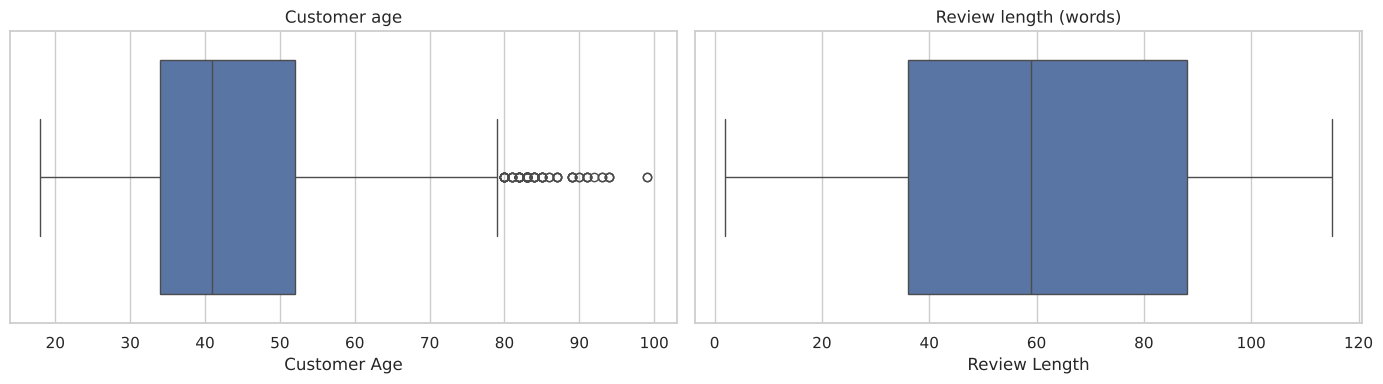

Customer Age: normal range 7 to 79, outliers = 108, min = 18, max = 99
Review Length: normal range -42 to 166, outliers = 0, min = 2, max = 115


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df["Customer Age"], ax=axes[0], color="#4c72b0")
axes[0].set_title("Customer age")
sns.boxplot(x=df["Review Length"], ax=axes[1], color="#4c72b0")
axes[1].set_title("Review length (words)")
plt.tight_layout()
plt.savefig("01_outliers.png", dpi=120)
plt.show()

for col in ["Customer Age", "Review Length"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: normal range {low:.0f} to {high:.0f}, outliers = {n_out}, min = {df[col].min()}, max = {df[col].max()}")

**Decision:** age outliers are customers above about 80 years old (oldest is 99). This is rare but possible, so we **keep** them. Reviews have a word limit on the website, so review length has no outliers above the top. Nothing is removed.

## 4. Exploratory analysis (EDA)

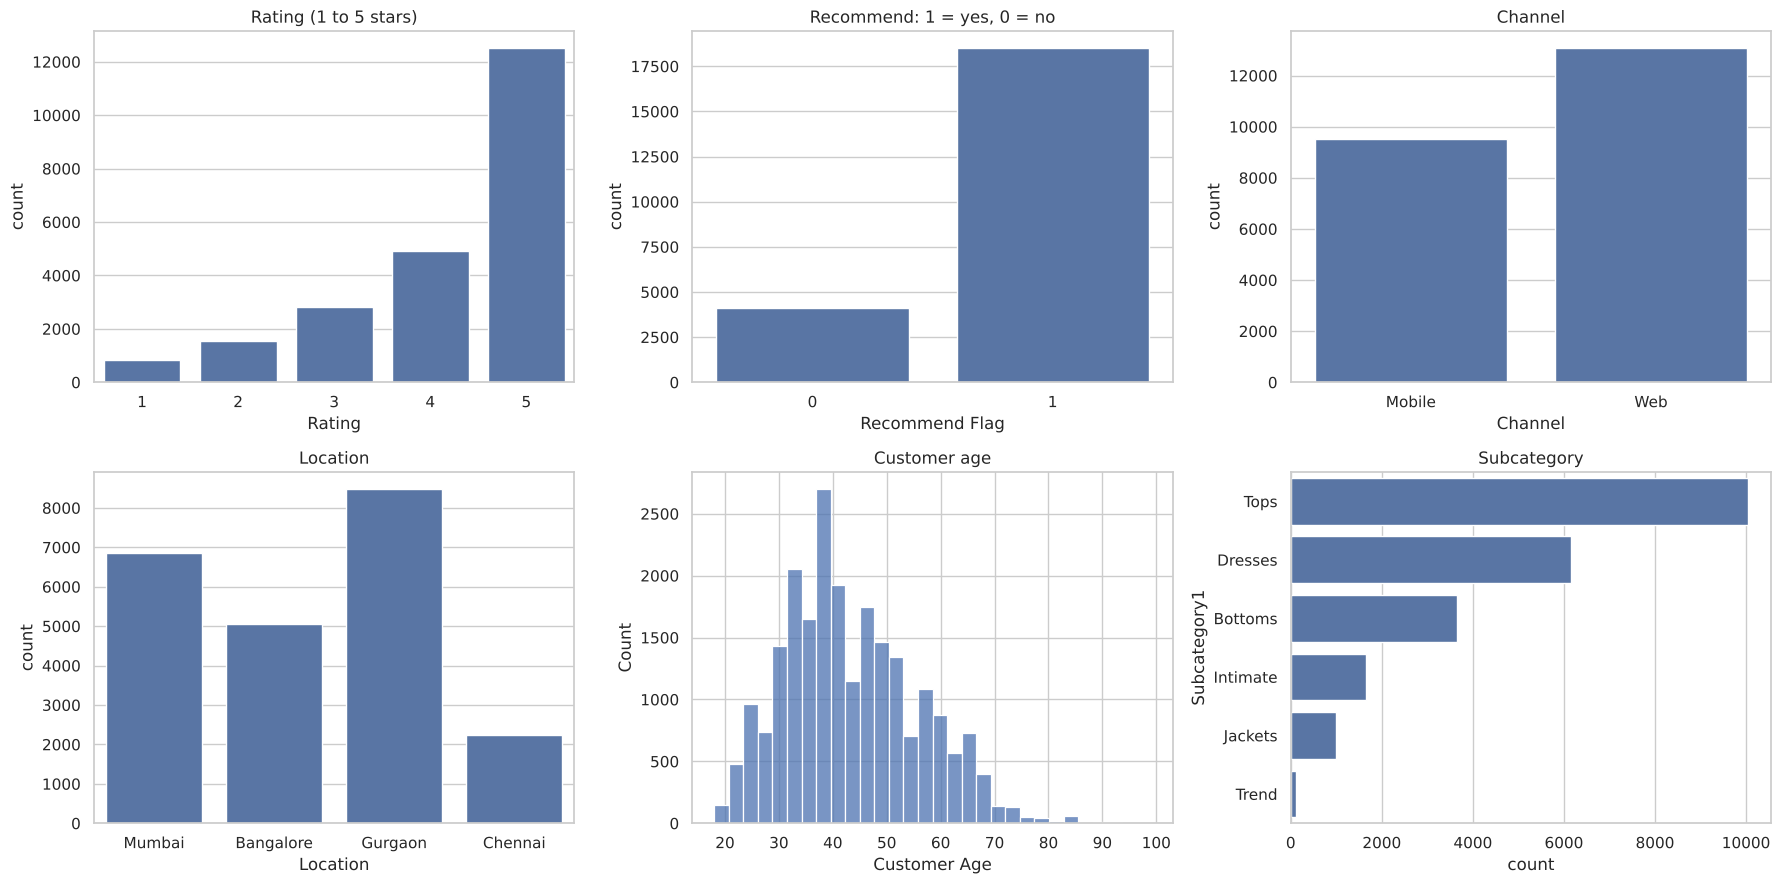

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.countplot(x="Rating", data=df, ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set_title("Rating (1 to 5 stars)")
sns.countplot(x="Recommend Flag", data=df, ax=axes[0, 1], color="#4c72b0")
axes[0, 1].set_title("Recommend: 1 = yes, 0 = no")
sns.countplot(x="Channel", data=df, ax=axes[0, 2], color="#4c72b0")
axes[0, 2].set_title("Channel")
sns.countplot(x="Location", data=df, ax=axes[1, 0], color="#4c72b0")
axes[1, 0].set_title("Location")
sns.histplot(df["Customer Age"], bins=30, ax=axes[1, 1], color="#4c72b0")
axes[1, 1].set_title("Customer age")
sns.countplot(y="Subcategory1", data=df, ax=axes[1, 2], color="#4c72b0",
              order=df["Subcategory1"].value_counts().index)
axes[1, 2].set_title("Subcategory")
plt.tight_layout()
plt.savefig("02_overview.png", dpi=120)
plt.show()

In [7]:
df["Age Group"] = pd.cut(df["Customer Age"], bins=[17, 25, 35, 45, 55, 65, 100],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"])

for col in ["Category", "Subcategory1", "Location", "Channel", "Age Group"]:
    t = df.groupby(col, observed=True).agg(Reviews=("Rating", "size"),
                                          Avg_Rating=("Rating", "mean"),
                                          Recommend_Rate=("Recommend Flag", "mean")).round(2)
    print(f"\n--- {col} ---")
    print(t)

print("\n--- Recommend rate by rating ---")
print(df.groupby("Rating")["Recommend Flag"].mean().round(2))


--- Category ---
                Reviews  Avg_Rating  Recommend_Rate
Category                                           
General           13365        4.17            0.81
General Petite     7837        4.20            0.82
Intimates          1426        4.28            0.85

--- Subcategory1 ---
              Reviews  Avg_Rating  Recommend_Rate
Subcategory1                                     
Bottoms          3662        4.28            0.85
Dresses          6145        4.14            0.81
Intimate         1653        4.27            0.85
Jackets          1002        4.25            0.83
Tops            10048        4.16            0.81
Trend             118        3.84            0.75

--- Location ---
           Reviews  Avg_Rating  Recommend_Rate
Location                                      
Bangalore     5048        4.18            0.82
Chennai       2238        4.19            0.82
Gurgaon       8486        4.18            0.82
Mumbai        6856        4.19            0.82


**What we see:**
- Most customers are happy: about 56% give 5 stars and 82% recommend.
- The data is **imbalanced**: only 18% do not recommend. We must handle this in the models.
- Location and channel make almost no difference (all about 4.2 stars).
- "Trend" items get the lowest rating (3.8). Customers aged 26-35 are the least happy group.
- Rating and recommend are strongly linked: almost nobody with 1-2 stars recommends, almost everybody with 4-5 stars does.

## 5. Text cleaning (the NLP pipeline)

These are the steps from my class notes. First we show each step on **one example review**, so we can see what it does.

In [8]:
CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not", "can't": "can not",
    "couldn't": "could not", "won't": "will not", "wouldn't": "would not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not", "shouldn't": "should not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not", "i'm": "i am",
    "it's": "it is", "that's": "that is", "i've": "i have", "i'd": "i would", "i'll": "i will",
    "you're": "you are", "they're": "they are", "there's": "there is", "what's": "what is",
    "let's": "let us", "she's": "she is", "he's": "he is", "we're": "we are",
}

def expand_contractions(text):
    text = text.replace("\u2019", "'")          # curly apostrophe to normal one
    for short, full in CONTRACTIONS.items():
        text = re.sub(r"\b" + re.escape(short) + r"\b", full, text)
    return text

# Keep negation words: "not good" and "good" mean opposite things
NEGATIONS = {"not", "no", "nor", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

example = df.loc[2, "Full Review"]
print("0. Original:      ", example[:200])
s = example.lower();                         print("1. Lower case:    ", s[:200])
s = expand_contractions(s);                  print("2. Contractions:  ", s[:200])
s = re.sub(r"[^a-z\s]", " ", s);             print("3. No special characters or numbers:", s[:200])
s = re.sub(r"\s+", " ", s).strip();          print("4. No extra spaces:", s[:200])
tokens = nltk.word_tokenize(s);              print("5. Tokens:        ", tokens[:25])
tokens = [w for w in tokens if w not in STOP_WORDS]; print("6. No stopwords:  ", tokens[:25])
print("7a. Stemming:     ", [stemmer.stem(w) for w in tokens][:25])
print("7b. Lemmatization:", [lemmatizer.lemmatize(w) for w in tokens][:25])

0. Original:       Some major design flaws. I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so sm
1. Lower case:     some major design flaws. i had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so sm
2. Contractions:   some major design flaws. i had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so sm
3. No special characters or numbers: some major design flaws  i had such high hopes for this dress and really wanted it to work for me  i initially ordered the petite small  my usual size  but i found this to be outrageously small  so sm
4. No extra spaces: some major design flaws i had such high hopes for this dress and really wanted it 

7b. Lemmatization: ['major', 'design', 'flaw', 'high', 'hope', 'dress', 'really', 'wanted', 'work', 'initially', 'ordered', 'petite', 'small', 'usual', 'size', 'found', 'outrageously', 'small', 'small', 'fact', 'could', 'not', 'zip', 'reordered', 'petite']


### Stemming vs lemmatization

- **Stemming** just chops the end off a word. It is fast but can make non-words ("flies" becomes "fli").
- **Lemmatization** looks the word up in a dictionary and gives a real word ("flies" becomes "fly").

In [9]:
words = ["flies", "dresses", "running", "fitted", "comfortable", "beautifully", "returned", "sizes"]
pd.DataFrame({"Word": words,
              "Stemming": [stemmer.stem(w) for w in words],
              "Lemmatization": [lemmatizer.lemmatize(w) for w in words]})

,Word,Stemming,Lemmatization
0,flies,fli,fly
1,dresses,dress,dress
2,running,run,running
3,fitted,fit,fitted
4,comfortable,comfort,comfortable
5,beautifully,beauti,beautifully
6,returned,return,returned
7,sizes,size,size


We use **lemmatization**, because word clouds and topics need real, readable words. Now we clean all reviews with the same steps.

In [10]:
def clean_text(text):
    text = expand_contractions(text.lower())
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    return " ".join(lemmatizer.lemmatize(w) for w in tokens if (w not in STOP_WORDS and len(w) > 2) or w in NEGATIONS)

df["Clean Review"] = df["Full Review"].apply(clean_text)
df[["Full Review", "Clean Review"]].head()

,Full Review,Clean Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky sexy comfortable
1,Love this dress! it's sooo pretty. i happene...,love dress sooo pretty happened find store gla...
2,Some major design flaws. I had such high hopes...,major design flaw high hope dress really wante...
3,"My favorite buy!. I love, love, love this jump...",favorite buy love love love jumpsuit fun flirt...
4,Flattering shirt. This shirt is very flatterin...,flattering shirt shirt flattering due adjustab...


## 6. Sentiment

There are two ways to label each review as Positive, Neutral or Negative:

1. **VADER**: a ready-made tool that scores the text using a word list (no training).
2. **From the rating**: 4-5 stars = Positive, 3 = Neutral, 1-2 = Negative.

Let us check how well VADER agrees with the stars the customer actually gave.

In [11]:
sia = SentimentIntensityAnalyzer()
# VADER uses the ORIGINAL text, because CAPS and "!!!" are clues for it
df["VADER Score"] = df["Full Review"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["VADER Sentiment"] = pd.cut(df["VADER Score"], bins=[-1.01, -0.05, 0.05, 1.01],
                               labels=["Negative", "Neutral", "Positive"])
df["Sentiment"] = df["Rating"].map({1: "Negative", 2: "Negative", 3: "Neutral", 4: "Positive", 5: "Positive"})

print(pd.crosstab(df["Rating"], df["VADER Sentiment"]))
one_star = df[df["Rating"] == 1]
print(f"\nVADER calls {(one_star['VADER Sentiment'] == 'Positive').mean():.0%} of the 1-star reviews 'Positive'.")

VADER Sentiment  Negative  Neutral  Positive
Rating                                      
1                     295       30       496
2                     342       47      1160
3                     376       67      2380
4                     163       25      4720
5                     114       19     12394

VADER calls 60% of the 1-star reviews 'Positive'.


**Finding:** VADER is fooled by fashion reviews. A sentence like *"I really wanted to love this dress, the colour is beautiful, but it fits terribly"* has many happy words, so VADER says Positive, even with 1 star.

**Decision:** we use the **rating-based** sentiment for the rest of the project. It comes from the customer, so it is the true feeling.

In [12]:
print(df["Sentiment"].value_counts())

Sentiment
Positive    17435
Neutral      2823
Negative     2370
Name: count, dtype: int64


## 7. Most frequent words: positive vs negative

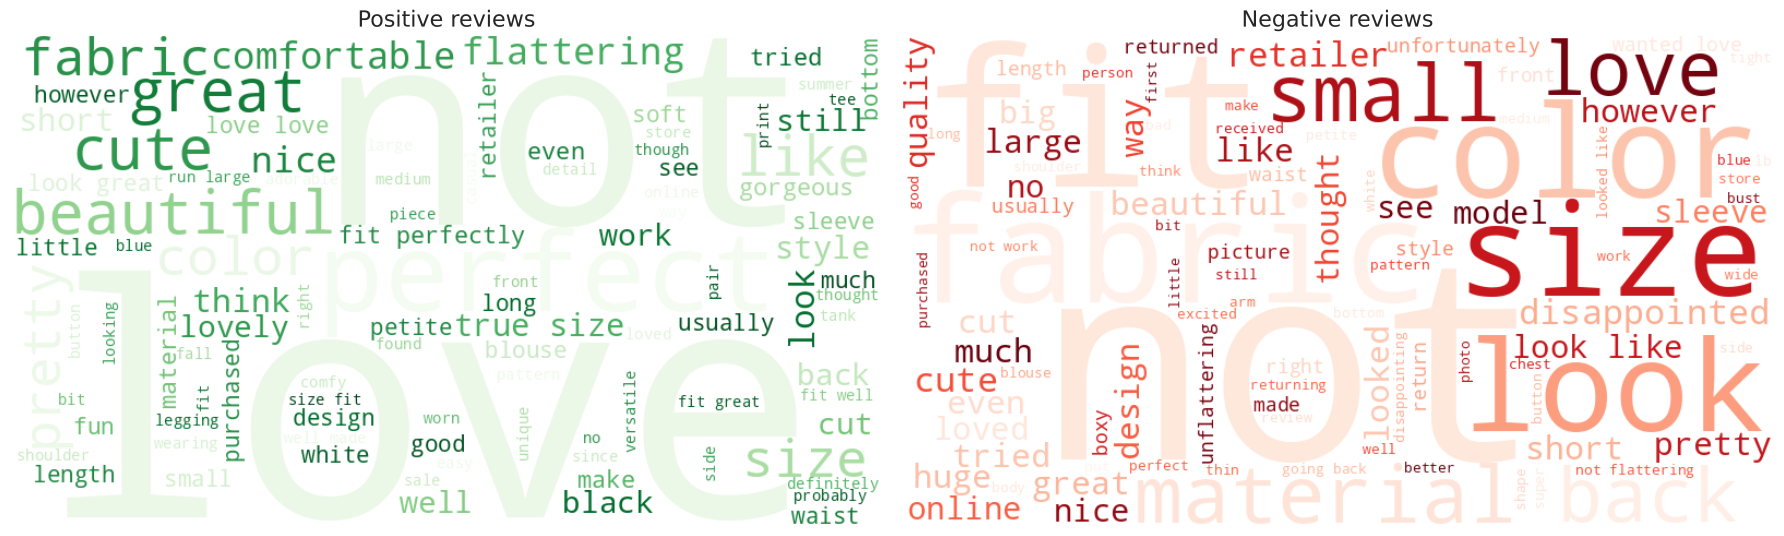

In [13]:
# Words that appear everywhere and tell us nothing about feelings
EXTRA_STOP = {"dress", "top", "shirt", "sweater", "pant", "jean", "skirt", "jacket", "wear", "wore",
              "bought", "ordered", "order", "one", "would", "get", "got", "really", "also", "could"}

def make_cloud(sentiment, ax, cmap):
    text = " ".join(df.loc[df["Sentiment"] == sentiment, "Clean Review"])
    wc = WordCloud(width=800, height=450, background_color="white", stopwords=EXTRA_STOP,
                   colormap=cmap, max_words=100, random_state=SEED).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{sentiment} reviews", fontsize=16)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
make_cloud("Positive", axes[0], "Greens")
make_cloud("Negative", axes[1], "Reds")
plt.tight_layout()
plt.savefig("03_wordclouds.png", dpi=120)
plt.show()

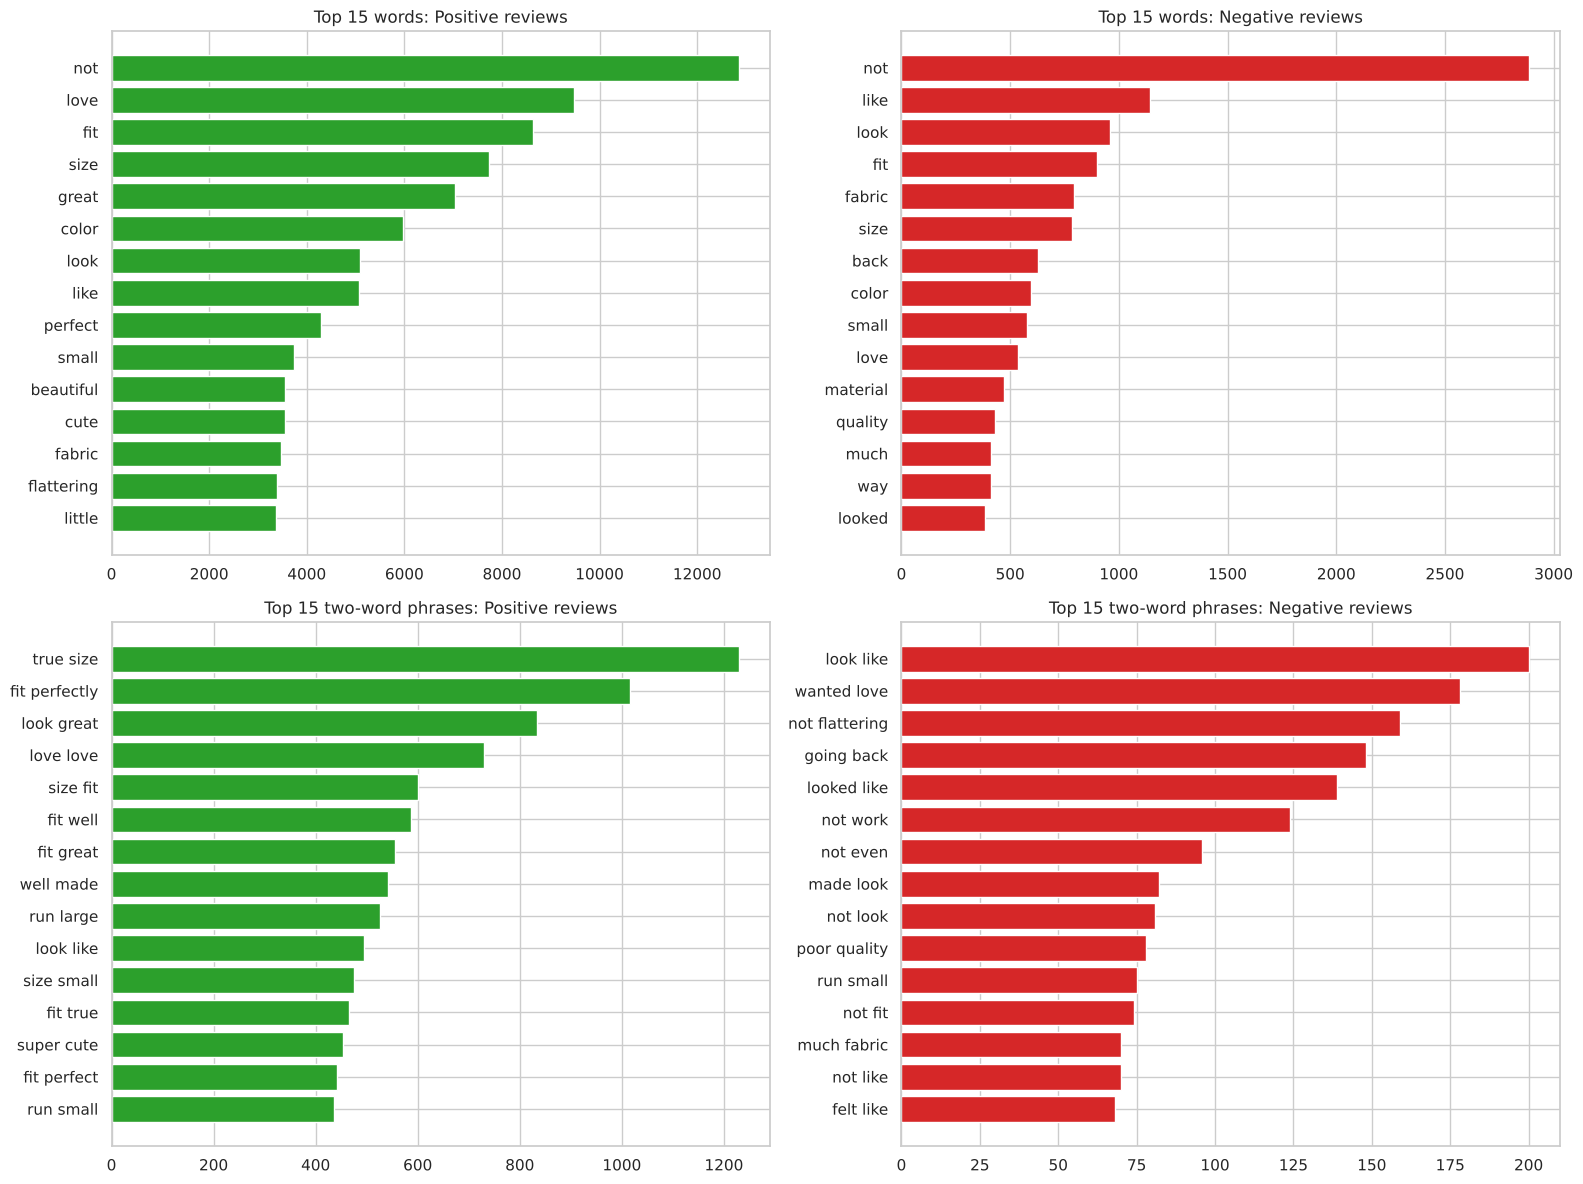

In [14]:
def top_ngrams(sentiment, n_words=(1, 1), top=15):
    texts = df.loc[df["Sentiment"] == sentiment, "Clean Review"]
    vec = CountVectorizer(ngram_range=n_words, min_df=5, stop_words=list(EXTRA_STOP))
    X = vec.fit_transform(texts)
    counts = X.sum(axis=0).A1
    return sorted(zip(vec.get_feature_names_out(), counts), key=lambda x: -x[1])[:top]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for row, (ngram, name) in enumerate([((1, 1), "words"), ((2, 2), "two-word phrases")]):
    for col, (sent, color) in enumerate([("Positive", "#2ca02c"), ("Negative", "#d62728")]):
        labels, counts = zip(*top_ngrams(sent, ngram))
        axes[row, col].barh(labels[::-1], counts[::-1], color=color)
        axes[row, col].set_title(f"Top 15 {name}: {sent} reviews")
plt.tight_layout()
plt.savefig("04_top_words.png", dpi=120)
plt.show()

**What we see:**
- Positive reviews talk about **love, perfect, beautiful, flattering, cute** and phrases like *"true size"*, *"fit perfectly"*, *"well made"*.
- Negative reviews talk about **fabric, material, quality, back** and phrases like *"wanted love"*, *"not flattering"*, *"going back"*, *"poor quality"*, *"not fit"*.
- "not" is the top word in both lists. That is why we kept it as a word: *"not flattering"* and *"flattering"* mean opposite things.
- Single words like "fit" and "size" appear in both, so **two-word phrases (bigrams)** tell the story better.

## 8. Sentiment by category, sub category, product, location, channel and age group

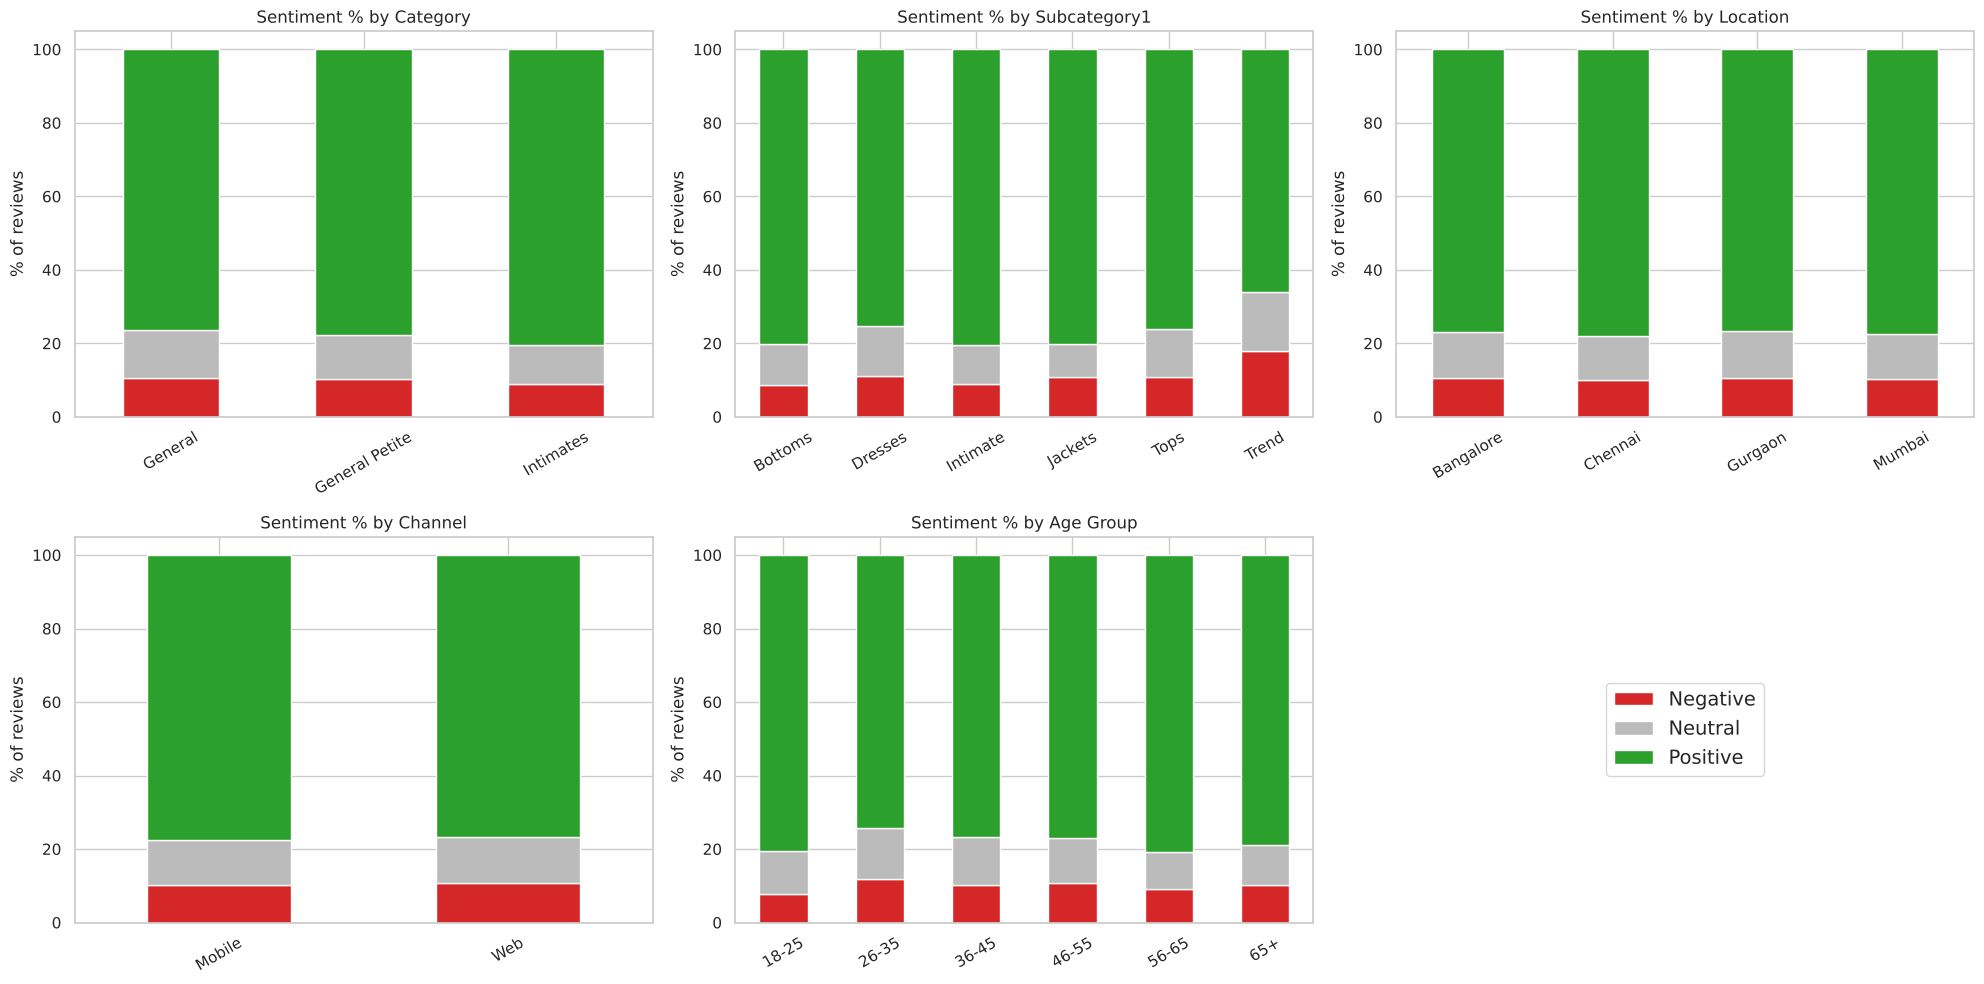

In [15]:
cols = ["Category", "Subcategory1", "Location", "Channel", "Age Group"]
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()
for ax, col in zip(axes, cols):
    pct = pd.crosstab(df[col], df["Sentiment"], normalize="index")[["Negative", "Neutral", "Positive"]] * 100
    pct.plot(kind="bar", stacked=True, ax=ax, color=["#d62728", "#bbbbbb", "#2ca02c"], legend=False)
    ax.set_title(f"Sentiment % by {col}")
    ax.set_ylabel("% of reviews")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=14)
plt.tight_layout()
plt.savefig("05_sentiment_by_group.png", dpi=120)
plt.show()

In [16]:
# Product type level (SubCategory2), only types with 100+ reviews
sub2 = pd.crosstab(df["SubCategory2"], df["Sentiment"], normalize="index") * 100
sub2["Reviews"] = df["SubCategory2"].value_counts()
print(sub2[sub2["Reviews"] >= 100].sort_values("Negative", ascending=False).round(1))

Sentiment     Negative  Neutral  Positive  Reviews
SubCategory2                                      
Trend             17.8     16.1      66.1      118
Blouses           11.5     12.9      75.6     2983
Swim              11.4     12.7      75.9      332
Outerwear         11.3      9.1      79.6      319
Dresses           11.1     13.5      75.4     6145
Sweaters          10.9     14.0      75.1     1380
Knits             10.8     13.1      76.2     4626
Sleep             10.7      7.5      81.8      214
Jackets           10.5      8.9      80.5      683
Legwear           10.1     10.1      79.7      158
Fine gauge         9.8     11.1      79.0     1059
Intimates          9.5     10.9      79.6      147
Skirts             9.4     11.5      79.1      903
Pants              9.0     11.4      79.6     1350
Shorts             8.2     12.8      78.9      304
Jeans              7.7     10.0      82.3     1104
Layering           7.6      6.8      85.6      132
Lounge             6.9     11.7

In [17]:
# Single product level (Product ID), only products with 50+ reviews so the % is reliable
prod = df.groupby("Product ID").agg(Reviews=("Rating", "size"),
                                    Subcategory=("SubCategory2", "first"),
                                    Avg_Rating=("Rating", "mean"),
                                    Negative_Pct=("Sentiment", lambda s: (s == "Negative").mean() * 100))
prod = prod[prod["Reviews"] >= 50].round(1)
print(f"{len(prod)} products have 50+ reviews.")
print("\nWORST 10 products (highest % negative):")
print(prod.sort_values("Negative_Pct", ascending=False).head(10))
print("\nBEST 10 products (lowest % negative):")
print(prod.sort_values("Negative_Pct").head(10))

98 products have 50+ reviews.

WORST 10 products (highest % negative):
            Reviews Subcategory  Avg_Rating  Negative_Pct
Product ID                                               
1084             72     Dresses         3.5          27.8
870              51       Knits         3.6          25.5
1087            124     Dresses         3.7          23.4
818              52     Blouses         3.7          23.1
844              50     Blouses         3.7          22.0
1082            142     Dresses         3.9          21.8
840              58     Blouses         3.8          20.7
1075             69     Dresses         3.8          18.8
1079             59     Dresses         3.6          18.6
941              81    Sweaters         4.0          18.5

BEST 10 products (lowest % negative):
            Reviews Subcategory  Avg_Rating  Negative_Pct
Product ID                                               
1060            101       Pants         4.3           4.0
964              73 

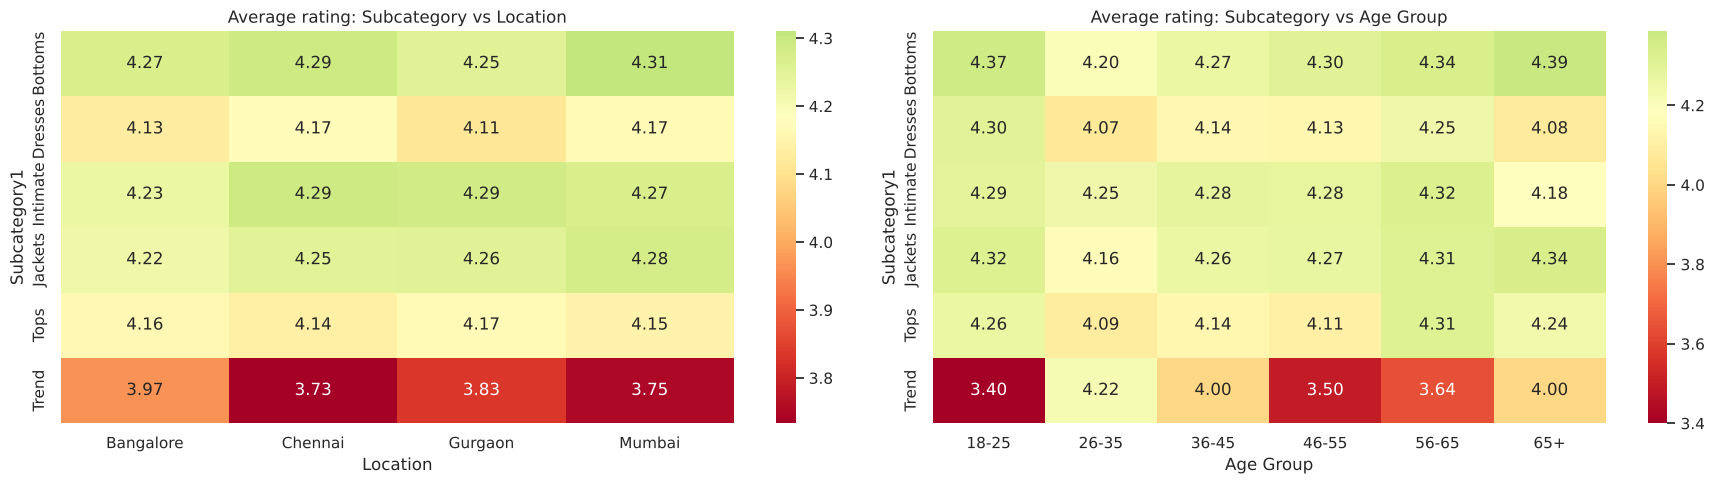

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, col in zip(axes, ["Location", "Age Group"]):
    pivot = df.pivot_table(index="Subcategory1", columns=col, values="Rating", aggfunc="mean", observed=True)
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", center=df["Rating"].mean(), ax=ax)
    ax.set_title(f"Average rating: Subcategory vs {col}")
plt.tight_layout()
plt.savefig("06_rating_heatmaps.png", dpi=120)
plt.show()

**What we see:**
- **Location and channel do not matter:** every city and both channels have about 10% negative reviews.
- **Trend** items are the most disliked (about 18% negative). Blouses, dresses and swimwear are next.
- Jeans, lounge wear and layering items are the safest.
- Some single products are much worse than their group (see the worst 10 list). These are the first products to check with the design or quality team.
- Customers aged **26-35** give the lowest rating in 4 of the 6 subcategories (bottoms, dresses, jackets, tops).

## 9. POS tagging (Part of Speech)

POS tagging labels each word as a noun, verb, adjective and so on. Here we use it to find the **adjectives** (describing words, tag starts with "JJ") customers use most. This shows *how* they describe the clothes.

In [19]:
print(nltk.pos_tag(nltk.word_tokenize("The fabric is cheap and the colour looks dull")))

[('The', 'DT'), ('fabric', 'NN'), ('is', 'VBZ'), ('cheap', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('colour', 'NN'), ('looks', 'VBZ'), ('dull', 'JJ')]


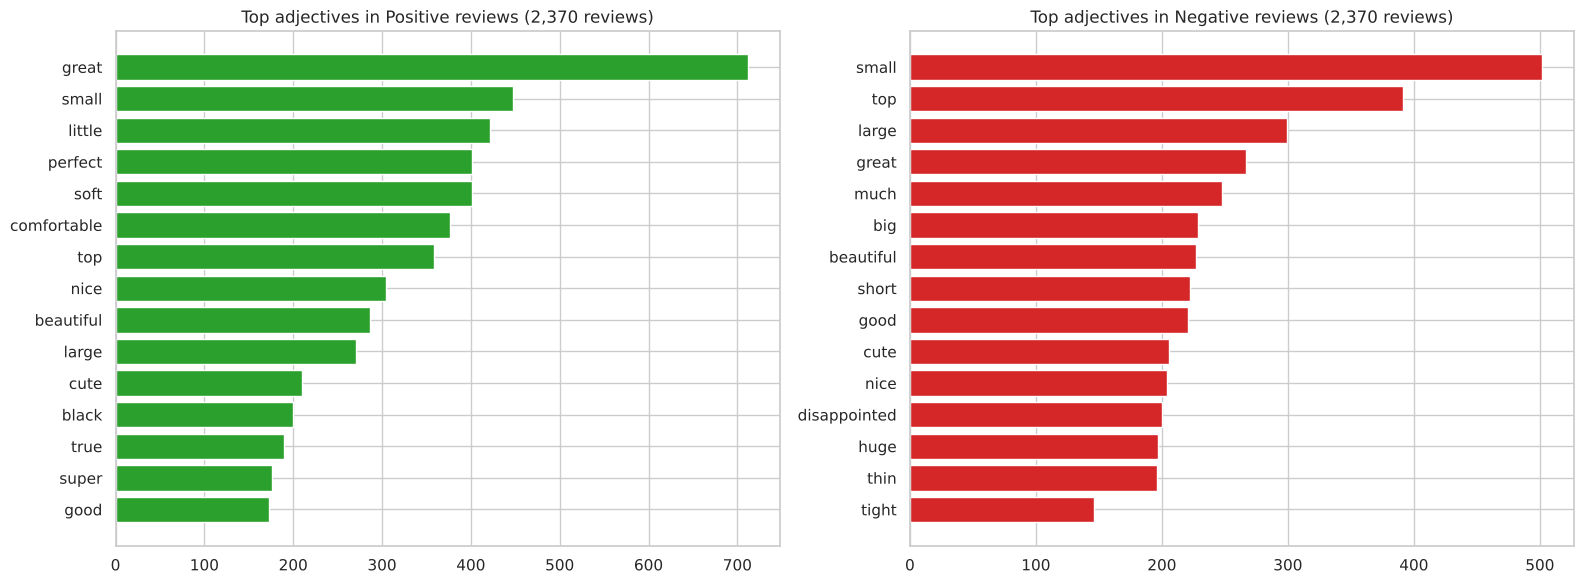

In [20]:
def top_adjectives(sentiment, n_reviews=3000, top=15):
    texts = df.loc[df["Sentiment"] == sentiment, "Review Text"].sample(n_reviews, random_state=SEED, replace=False)
    adjs = []
    for t in texts:
        for word, tag in nltk.pos_tag(nltk.word_tokenize(t.lower())):
            if tag.startswith("JJ") and word.isalpha() and word not in STOP_WORDS:
                adjs.append(word)
    return Counter(adjs).most_common(top)

n = min(3000, (df["Sentiment"] == "Negative").sum())
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (sent, color) in zip(axes, [("Positive", "#2ca02c"), ("Negative", "#d62728")]):
    labels, counts = zip(*top_adjectives(sent, n))
    ax.barh(labels[::-1], counts[::-1], color=color)
    ax.set_title(f"Top adjectives in {sent} reviews ({n:,} reviews)")
plt.tight_layout()
plt.savefig("07_pos_adjectives.png", dpi=120)
plt.show()

**What we see:** happy customers say *great, perfect, soft, comfortable, beautiful*. Unhappy customers say *small, large, big, short, huge, thin, tight, disappointed*: they are mostly unhappy about **size and fabric**.

## 10. NER (Named Entity Recognition)

NER finds names of people, places and organisations in text. Reviews are about clothes, so we expect very few entities. Let us check.

In [21]:
def tree_entities(tree):
    return [(" ".join(w for w, _ in st.leaves()), st.label()) for st in tree if hasattr(st, "label")]

demo = "I bought this at the Retailer store in New York and Sarah from Anthropologie loved it."
print(tree_entities(nltk.ne_chunk(nltk.pos_tag(nltk.word_tokenize(demo)))))

# ne_chunk_sents loads the NER model once for all reviews (much faster than one by one)
sample = df["Review Text"].sample(2000, random_state=SEED)
tagged = [nltk.pos_tag(nltk.word_tokenize(t)) for t in sample]
ents = [e for tree in nltk.ne_chunk_sents(tagged) for e in tree_entities(tree)]
ent_df = pd.DataFrame(ents, columns=["Entity", "Type"])
print(f"\nFound {len(ent_df)} entities in 2,000 reviews.")
print(ent_df["Type"].value_counts())
print("\nMost common entities:")
print(ent_df["Entity"].value_counts().head(15))

[('Retailer', 'ORGANIZATION'), ('New York', 'GPE'), ('Sarah', 'PERSON'), ('Anthropologie', 'PERSON')]



Found 183 entities in 2,000 reviews.
Type
GPE             174
PERSON            8
ORGANIZATION      1
Name: count, dtype: int64

Most common entities:
Entity
Great        30
Beautiful    17
Cute         12
Bought       10
Super         8
Saw           6
Got           6
Gorgeous      6
Love          6
Was           5
Perfect       5
Nice          4
Adorable      4
Looks         4
Dress         4
Name: count, dtype: int64


**What we see:** NER makes many mistakes here. Most "entities" are just the first word of a sentence, like *"Great"* or *"Beautiful"*. NER sees a capital letter and guesses it is a place or an organisation. Real names of people, places or brands are rare in clothing reviews.

**Lesson:** NER is very useful for news, contracts or emails, which are full of names. For product reviews it adds little, so we do not use it in the models.

## 11. Turning text into numbers

Machine learning models only understand numbers. My notes show two simple ways, on a tiny example:

- **Count Vectorizer:** counts how many times each word appears.
- **TF-IDF:** gives a high score to words that are common in this sentence but rare in the other sentences (more important words).

In [22]:
toy = ["king xyz popular", "king kind hearted"]
cv_toy = CountVectorizer()
print("Count Vectorizer:")
print(pd.DataFrame(cv_toy.fit_transform(toy).toarray(), columns=cv_toy.get_feature_names_out(), index=toy))

tf_toy = TfidfVectorizer()
print("\nTF-IDF:")
print(pd.DataFrame(tf_toy.fit_transform(toy).toarray(), columns=tf_toy.get_feature_names_out(), index=toy).round(2))

Count Vectorizer:
                   hearted  kind  king  popular  xyz
king xyz popular         0     0     1        1    1
king kind hearted        1     1     1        0    0

TF-IDF:
                   hearted  kind  king  popular   xyz
king xyz popular      0.00  0.00  0.45     0.63  0.63
king kind hearted     0.63  0.63  0.45     0.00  0.00


"king" is in both sentences, so TF-IDF gives it a **lower** score than the other words. That is the idea: shared words are less important.

We also use **n-grams** (`ngram_range=(1, 2)` keeps single words and two-word phrases like "not flattering") and **min_df** (`min_df=5` ignores words that appear in fewer than 5 reviews).

## 12. Predict who recommends the product

**Target:** Recommend Flag (1 = yes, 0 = no). **Input:** the cleaned review text.

Only 18% say "no", so plain accuracy is misleading (a model that always says "yes" gets 82%). We use **macro F1**: the average F1 of both classes, so the "no" class counts equally. We also use `class_weight="balanced"` so the model pays more attention to the "no" customers.

We keep 20% of the data as a **test set** that no model sees until the end.

In [23]:
X = df["Clean Review"]
y = df["Recommend Flag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", len(X_train), "| Test:", len(X_test))

results = {}   # test-set macro F1 of every model, for the final comparison

Train: 18102 | Test: 4526


### 12.1 Compare three models with 5-fold cross validation

In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
    "Complement Naive Bayes": ComplementNB(),
}
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=20000)),
                     ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=kfold, scoring="f1_macro", n_jobs=-1)
    print(f"{name:25s} macro F1 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression       macro F1 = 0.843 (+/- 0.008)


Linear SVM                macro F1 = 0.846 (+/- 0.007)


Complement Naive Bayes    macro F1 = 0.837 (+/- 0.007)


### 12.2 Tune the best settings with GridSearchCV

In [25]:
pipe = Pipeline([("tfidf", TfidfVectorizer(min_df=5, sublinear_tf=True)),
                 ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
params = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [20000, 40000],
    "clf__C": [0.3, 1, 3, 10],
}
grid = GridSearchCV(pipe, params, cv=kfold, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)
print("Best cross-validation macro F1:", round(grid.best_score_, 3))

Best settings: {'clf__C': 10, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 3)}
Best cross-validation macro F1: 0.851


We tune **Logistic Regression** (not the SVM, which scored about the same) because its word weights are easy to explain, and it gives probabilities. Now the final check on the test set.

               precision    recall  f1-score   support

Not recommend       0.71      0.78      0.74       820
    Recommend       0.95      0.93      0.94      3706

     accuracy                           0.90      4526
    macro avg       0.83      0.85      0.84      4526
 weighted avg       0.91      0.90      0.90      4526



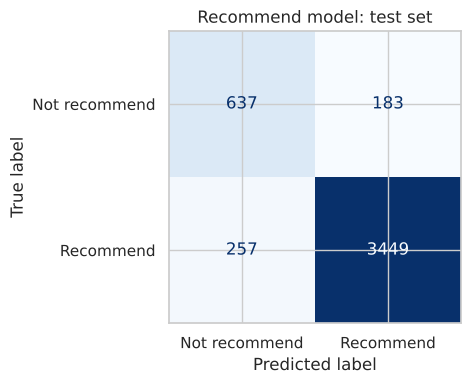

In [26]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test)
results["TF-IDF + Logistic Regression (tuned)"] = f1_score(y_test, pred, average="macro")
print(classification_report(y_test, pred, target_names=["Not recommend", "Recommend"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Not recommend", "Recommend"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Recommend model: test set")
plt.tight_layout()
plt.savefig("08_confusion_matrix.png", dpi=120)
plt.show()

### 12.3 Which words drive recommending?

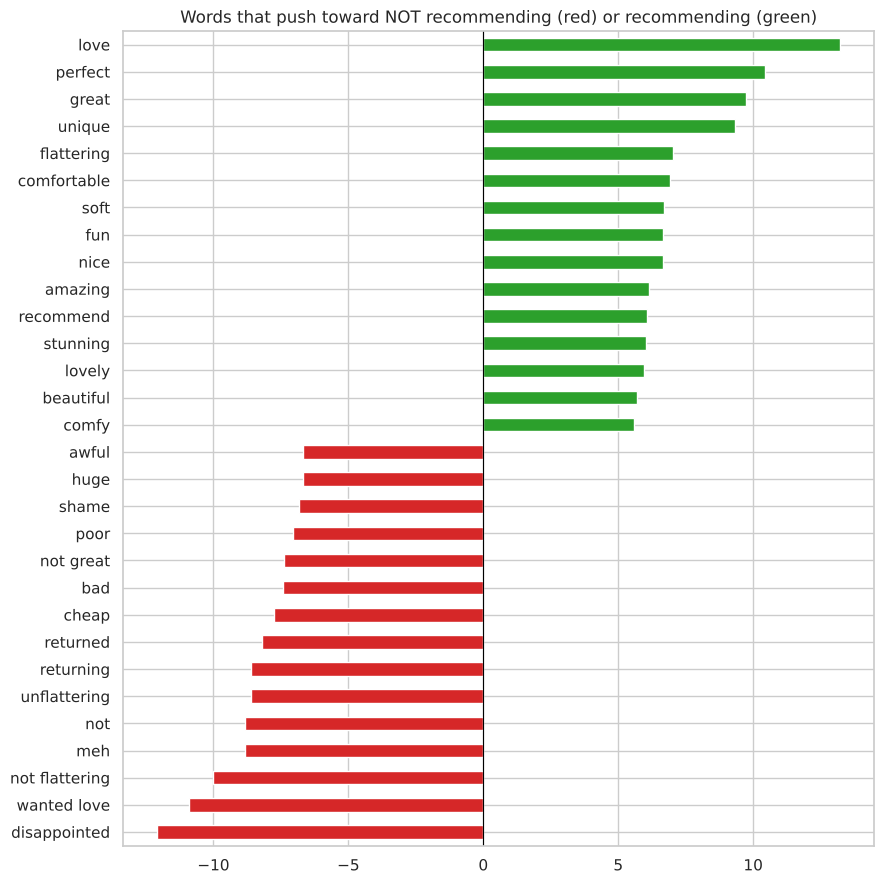

In [27]:
vec = best_model.named_steps["tfidf"]
coef = pd.Series(best_model.named_steps["clf"].coef_[0], index=vec.get_feature_names_out()).sort_values()
drivers = pd.concat([coef.head(15), coef.tail(15)])

plt.figure(figsize=(9, 9))
drivers.plot(kind="barh", color=["#d62728"] * 15 + ["#2ca02c"] * 15)
plt.title("Words that push toward NOT recommending (red) or recommending (green)")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.savefig("09_word_drivers.png", dpi=120)
plt.show()

### 12.4 Word embeddings: GloVe (pre-trained) and FastText (trained on our reviews)

TF-IDF treats "comfy" and "comfortable" as totally different words. **Word embeddings** fix this: each word becomes a list of numbers (a vector), and words with similar meaning get similar vectors.

- **GloVe** (from Stanford): already trained on Wikipedia. Each word is 100 numbers. We just download and use it.
- **FastText** (from Facebook): we train it on our own reviews. It also looks at parts of words, so it can handle spelling mistakes like "gooood".

To get one vector for a whole review, we take the **average** of its word vectors. (As my notes say, this ignores the word order.)

In [28]:
import gensim.downloader as api
from gensim.models import FastText

glove = api.load("glove-wiki-gigaword-100")     # about 130 MB, downloaded once
print("GloVe words similar to 'comfortable':", [w for w, _ in glove.most_similar("comfortable", topn=6)])

train_tokens = [t.split() for t in X_train]
fasttext = FastText(sentences=train_tokens, vector_size=100, window=5, min_count=3, epochs=10, seed=SEED, workers=1)
print("FastText words similar to 'comfortable':", [w for w, _ in fasttext.wv.most_similar("comfortable", topn=6)])
print("FastText words similar to the spelling mistake 'gooood':", [w for w, _ in fasttext.wv.most_similar("gooood", topn=4)])

GloVe words similar to 'comfortable': ['looking', 'easy', 'staying', 'enjoying', 'feel', 'better']


FastText words similar to 'comfortable': ['comfotable', 'comfort', 'confortable', 'comfortably', 'comfrotable', 'comf']
FastText words similar to the spelling mistake 'gooood': ['good', 'god', 'mood', 'goodness']


In [29]:
def doc_vectors(texts, wv, size=100):
    out = np.zeros((len(texts), size))
    for i, t in enumerate(texts):
        vecs = [wv[w] for w in t.split() if w in wv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out

for name, wv in [("GloVe", glove), ("FastText", fasttext.wv)]:
    Xtr, Xte = doc_vectors(X_train, wv), doc_vectors(X_test, wv)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, y_train)
    results[f"{name} average + Logistic Regression"] = f1_score(y_test, clf.predict(Xte), average="macro")
    print(f"{name:9s} test macro F1 = {results[f'{name} average + Logistic Regression']:.3f}")

GloVe     test macro F1 = 0.736


FastText  test macro F1 = 0.786


**What we see:**
- GloVe learned English from Wikipedia, so its "similar words" for *comfortable* are general (*easy, feel, better*). It does not know fashion.
- FastText learned from our own reviews. It found real spelling mistakes customers make (*comfotable, confortable*) and knows *gooood* means *good*.
- Both are weaker than TF-IDF here, because taking the average of all word vectors loses words like "not".

### 12.5 Deep learning: LSTM and GRU

Averaging word vectors loses the **order** of words ("not good, but cute" vs "good, but not cute"). **RNN** models read words one by one and remember what came before:

- **LSTM** (Long Short-Term Memory): has a *forget gate*, so it can remember information over long text.
- **GRU** (Gated Recurrent Unit): similar idea, fewer calculations, so it is faster.

Steps: turn each word into a number (its position in the vocabulary), make every review the same length (100 words), then train. We use the original text with light cleaning, because these models can use word order and small words like "but" and "not".

In [30]:
import tensorflow as tf
from tensorflow.keras import layers

tf.random.set_seed(SEED)
MAX_WORDS, MAX_LEN = 20000, 100

def light_clean(text):
    text = expand_contractions(text.lower())
    return re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", text)).strip()

raw_train = df.loc[X_train.index, "Full Review"].apply(light_clean).values
raw_test = df.loc[X_test.index, "Full Review"].apply(light_clean).values

vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=MAX_LEN)
vectorizer.adapt(raw_train)
seq_train, seq_test = vectorizer(raw_train), vectorizer(raw_test)
print("Example review as numbers:", seq_train[0][:15].numpy())

weights = {0: len(y_train) / (2 * (y_train == 0).sum()), 1: len(y_train) / (2 * (y_train == 1).sum())}

def build(rnn_layer):
    model = tf.keras.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(MAX_WORDS, 64, mask_zero=True),
        rnn_layer,
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

histories = {}
for name, rnn in [("LSTM", layers.LSTM(64)), ("GRU", layers.GRU(64))]:
    model = build(rnn)
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)
    histories[name] = model.fit(seq_train, y_train.values, validation_split=0.1, epochs=6, batch_size=128,
                                class_weight=weights, callbacks=[stop], verbose=0)
    p = (model.predict(seq_test, verbose=0).ravel() > 0.5).astype(int)
    results[name] = f1_score(y_test, p, average="macro")
    print(f"{name}: trained {len(histories[name].history['loss'])} epochs, test macro F1 = {results[name]:.3f}")

Example review as numbers: [ 18 167  22   8   4 220   5 376  10  56  95   2  43   4 122]


LSTM: trained 4 epochs, test macro F1 = 0.836


GRU: trained 4 epochs, test macro F1 = 0.832


### 12.6 All recommend models compared (same test set)

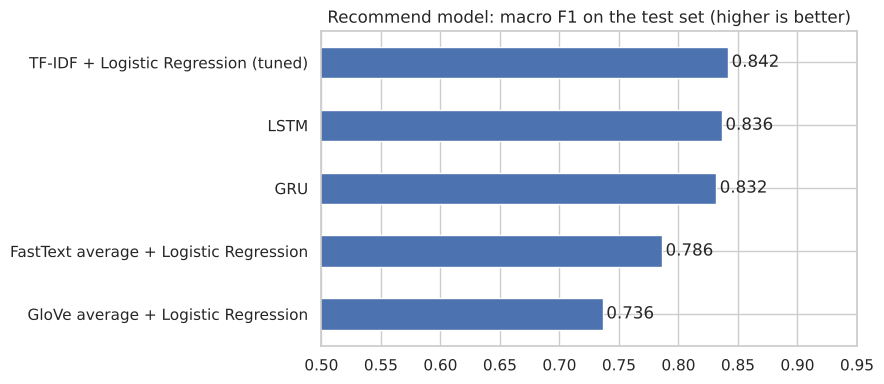

TF-IDF + Logistic Regression (tuned)      0.842
LSTM                                      0.836
GRU                                       0.832
FastText average + Logistic Regression    0.786
GloVe average + Logistic Regression       0.736
dtype: float64

In [31]:
comp = pd.Series(results).sort_values()
plt.figure(figsize=(9, 4))
comp.plot(kind="barh", color="#4c72b0")
for i, v in enumerate(comp):
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.xlim(0.5, 0.95)
plt.title("Recommend model: macro F1 on the test set (higher is better)")
plt.tight_layout()
plt.savefig("10_model_comparison.png", dpi=120)
plt.show()
comp.sort_values(ascending=False).round(3)

**What we see:** the simple **TF-IDF + Logistic Regression** model is the best, but only by a little. LSTM and GRU come very close, because they read the words in order. They are much better than the averaged word embeddings (GloVe, FastText), which lose the order. With only about 18,000 training reviews, deep learning does not have enough data to clearly win. TF-IDF + Logistic Regression is also much faster and easier to explain, so we keep it as the final model.

*Note: LSTM and GRU scores can change a little each time you run them.*

## 13. Drivers of recommending: customer details

The PDF also asks: are some **types of customers** more likely to recommend? Here we ignore the text and use only age group, category, subcategory, channel and location.

Customer-details-only model: test macro F1 = 0.458


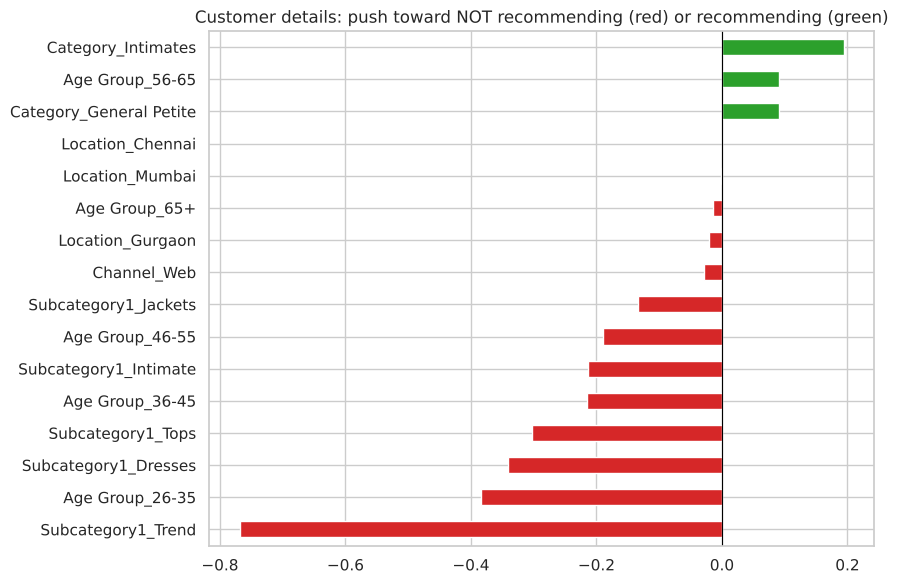

Strongest push to NOT recommend: [('Subcategory1_Trend', -0.77), ('Age Group_26-35', -0.38), ('Subcategory1_Dresses', -0.34), ('Subcategory1_Tops', -0.3)]
Strongest push to recommend:    [('Location_Chennai', -0.0), ('Category_General Petite', 0.09), ('Age Group_56-65', 0.09), ('Category_Intimates', 0.19)]


In [32]:
meta_cols = ["Age Group", "Category", "Subcategory1", "Channel", "Location"]
meta = pd.get_dummies(df[meta_cols].astype(str), drop_first=True).astype(int)
m_train, m_test = meta.loc[X_train.index], meta.loc[X_test.index]

meta_model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(m_train, y_train)
print(f"Customer-details-only model: test macro F1 = {f1_score(y_test, meta_model.predict(m_test), average='macro'):.3f}")

meta_coef = pd.Series(meta_model.coef_[0], index=meta.columns).sort_values()
plt.figure(figsize=(9, 6))
meta_coef.plot(kind="barh", color=["#d62728" if v < 0 else "#2ca02c" for v in meta_coef])
plt.axvline(0, color="black", lw=0.8)
plt.title("Customer details: push toward NOT recommending (red) or recommending (green)")
plt.tight_layout()
plt.savefig("11_customer_drivers.png", dpi=120)
plt.show()
print("Strongest push to NOT recommend:", list(meta_coef.head(4).round(2).items()))
print("Strongest push to recommend:   ", list(meta_coef.tail(4).round(2).items()))

**What we see:** customer details alone predict almost nothing (macro F1 close to 0.5, which is like guessing). The effects are small: **Trend** items, the **26-35** age group, **dresses** and **tops** lean toward "not recommend". **Intimates** and the **56-65** age group lean a little toward "recommend". Location and channel have almost no effect.

**Conclusion:** *what* the customer says about the product (fit, fabric, quality) drives recommending, not *who* the customer is.

## 14. Predict the star rating from the review

Now the target is the rating (1 to 5). We try two ways:
1. **Classification:** treat each star as a class.
2. **Regression (Ridge):** predict a number like 3.7, then round it to the nearest star.

In [33]:
y_r = df["Rating"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_r, test_size=0.2, random_state=SEED, stratify=y_r)

clf_pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=40000, sublinear_tf=True)),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
reg_pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=40000, sublinear_tf=True)),
                     ("reg", Ridge(alpha=1.0))])
clf_pipe.fit(Xr_train, yr_train)
reg_pipe.fit(Xr_train, yr_train)

pred_c = clf_pipe.predict(Xr_test)
pred_r = np.clip(np.rint(reg_pipe.predict(Xr_test)), 1, 5).astype(int)

rating_table = pd.DataFrame({
    "Exact star correct": [accuracy_score(yr_test, p) for p in (pred_c, pred_r)],
    "Average miss (stars)": [mean_absolute_error(yr_test, p) for p in (pred_c, pred_r)],
    "Within 1 star": [(abs(yr_test - p) <= 1).mean() for p in (pred_c, pred_r)],
}, index=["Classification (Logistic Regression)", "Regression (Ridge, rounded)"]).round(3)
print(rating_table)
print("\nClassification model, per star:")
print(classification_report(yr_test, pred_c))

                                      Exact star correct  \
Classification (Logistic Regression)               0.616   
Regression (Ridge, rounded)                        0.585   

                                      Average miss (stars)  Within 1 star  
Classification (Logistic Regression)                 0.468          0.932  
Regression (Ridge, rounded)                          0.459          0.961  

Classification model, per star:
              precision    recall  f1-score   support

           1       0.38      0.40      0.39       164
           2       0.31      0.37      0.34       310
           3       0.38      0.42      0.40       565
           4       0.41      0.46      0.43       982
           5       0.84      0.77      0.80      2505

    accuracy                           0.62      4526
   macro avg       0.47      0.48      0.47      4526
weighted avg       0.64      0.62      0.63      4526



**What we see:** guessing the exact star is hard (about 60% correct), because 4 and 5 stars, or 1 and 2 stars, read very similarly. But the model is usually close: it misses by about **half a star** on average and is **within 1 star over 90%** of the time. The classification model is better at finding the rare 1-star and 2-star reviews, so we prefer it.

## 15. Topic mining (LDA)

**LDA** (Latent Dirichlet Allocation) reads all reviews and finds groups of words that often appear together. Each group is a **topic**. We must choose the number of topics ourselves.

We remove very common "feeling" words (love, great, fit, size...), so the topics show *what* people talk about, not *how much* they like it.

To choose the number of topics we use a **coherence score** (NPMI): it checks if the top words of each topic really appear together in reviews. Higher is better.

4 topics: coherence = 0.0598


5 topics: coherence = 0.0674


6 topics: coherence = 0.0570


7 topics: coherence = 0.0629


8 topics: coherence = 0.0568


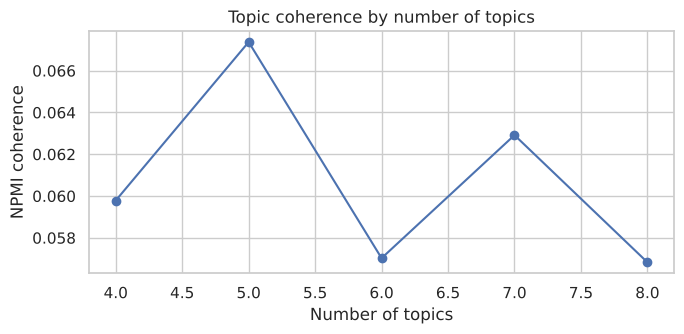

In [34]:
GENERIC = {"love", "great", "like", "look", "looked", "perfect", "nice", "well", "much", "little", "bit",
           "beautiful", "cute", "not", "just", "way", "even", "good", "fit", "size", "color", "colour", "no"}
cv_lda = CountVectorizer(max_df=0.4, min_df=10, stop_words=list(EXTRA_STOP | GENERIC))
dtm = cv_lda.fit_transform(df["Clean Review"])
vocab = cv_lda.get_feature_names_out()
B = (dtm > 0).astype(np.float32).tocsc()

def npmi_coherence(model, top_n=10):
    N, eps, scores = B.shape[0], 1e-12, []
    for topic in model.components_:
        idx = topic.argsort()[-top_n:]
        sub = B[:, idx]
        co = (sub.T @ sub).toarray() / N
        p = np.asarray(sub.sum(axis=0)).ravel() / N
        vals = [np.log((co[i, j] + eps) / (p[i] * p[j])) / (-np.log(co[i, j] + eps))
                for i in range(top_n) for j in range(i + 1, top_n)]
        scores.append(np.mean(vals))
    return np.mean(scores)

lda_models, coherence = {}, {}
for k in range(4, 9):
    lda_models[k] = LatentDirichletAllocation(n_components=k, random_state=SEED, learning_method="online",
                                              max_iter=10, n_jobs=-1).fit(dtm)
    coherence[k] = npmi_coherence(lda_models[k])
    print(f"{k} topics: coherence = {coherence[k]:.4f}")

pd.Series(coherence).plot(marker="o", figsize=(7, 3.5), title="Topic coherence by number of topics")
plt.xlabel("Number of topics")
plt.ylabel("NPMI coherence")
plt.tight_layout()
plt.show()

In [35]:
BEST_K = max(coherence, key=coherence.get)
lda = lda_models[BEST_K]
print(f"Best number of topics = {BEST_K}\n")
for i, topic in enumerate(lda.components_):
    print(f"Topic {i}: {', '.join(vocab[j] for j in topic.argsort()[-12:][::-1])}")

Best number of topics = 5

Topic 0: small, run, large, medium, usually, flattering, lb, waist, enough, big, normally, tank
Topic 1: fabric, back, bra, see, front, flowy, cut, material, wash, lace, photo, neck
Topic 2: soft, comfortable, fall, flattering, fabric, summer, black, quality, material, price, feel, sleeve
Topic 3: store, online, tried, saw, without, retailer, try, pocket, person, first, loved, sale
Topic 4: petite, fabric, short, back, small, arm, waist, length, big, work, however, long


                                        Reviews  Avg_Rating  Recommend_Rate  \
Topic Name                                                                    
Petite fit and length                      6793        3.46            0.60   
Fabric, see-through and design details     1681        3.97            0.76   
Shopping: in store vs online               1511        4.50            0.89   
Sizing (runs small or large)               3561        4.47            0.92   
Comfort and everyday wear                  9082        4.60            0.94   

                                        Negative_Pct  
Topic Name                                            
Petite fit and length                          22.60  
Fabric, see-through and design details         14.99  
Shopping: in store vs online                    7.41  
Sizing (runs small or large)                    4.41  
Comfort and everyday wear                       3.46  


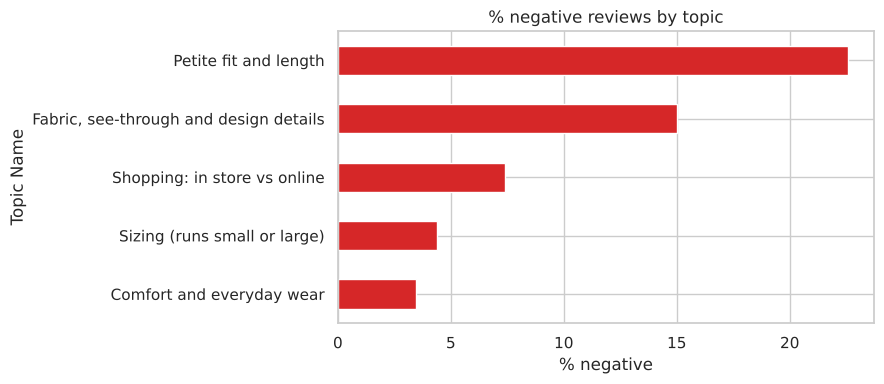

In [36]:
TOPIC_NAMES = {
    0: "Sizing (runs small or large)",
    1: "Fabric, see-through and design details",
    2: "Comfort and everyday wear",
    3: "Shopping: in store vs online",
    4: "Petite fit and length",
}

df["Topic"] = lda.transform(dtm).argmax(axis=1)
df["Topic Name"] = df["Topic"].map(TOPIC_NAMES)

topic_summary = df.groupby("Topic Name").agg(
    Reviews=("Rating", "size"),
    Avg_Rating=("Rating", "mean"),
    Recommend_Rate=("Recommend Flag", "mean"),
    Negative_Pct=("Sentiment", lambda s: (s == "Negative").mean() * 100),
).round(2).sort_values("Negative_Pct", ascending=False)
print(topic_summary)

topic_summary["Negative_Pct"].sort_values().plot(kind="barh", color="#d62728", figsize=(9, 4))
plt.title("% negative reviews by topic")
plt.xlabel("% negative")
plt.tight_layout()
plt.savefig("12_topics.png", dpi=120)
plt.show()

**The 5 themes customers talk about:**

| Topic | Top words | What it means |
|---|---|---|
| Comfort and everyday wear | soft, comfortable, summer, quality, price | Happy customers praising daily-wear items |
| Sizing | small, run, large, medium, usually, lb | "It runs small, order one size up" |
| Shopping: in store vs online | store, online, tried, saw, retailer, sale | Where and how they bought it |
| Fabric, see-through and design details | fabric, back, bra, see, lace, wash, photo | Thin fabric, needs a bra, looks different from the photo |
| Petite fit and length | petite, short, back, arm, waist, length | The cut does not fit the body: too short, too long, tight arms |

**What we see:**
- **Petite fit and length** is the biggest problem: about 1 in 4 of these reviews is negative, and only about 60% recommend.
- **Fabric and see-through** issues come second.
- **Sizing** talk is common but not very negative: customers just warn others to order a different size, and still keep the item.
- **Comfort** reviews are the happiest group.

## 16. Dashboard

One picture with the most important results, plus an interactive HTML dashboard (`dashboard.html`) where you can hover over the bars and switch between charts.

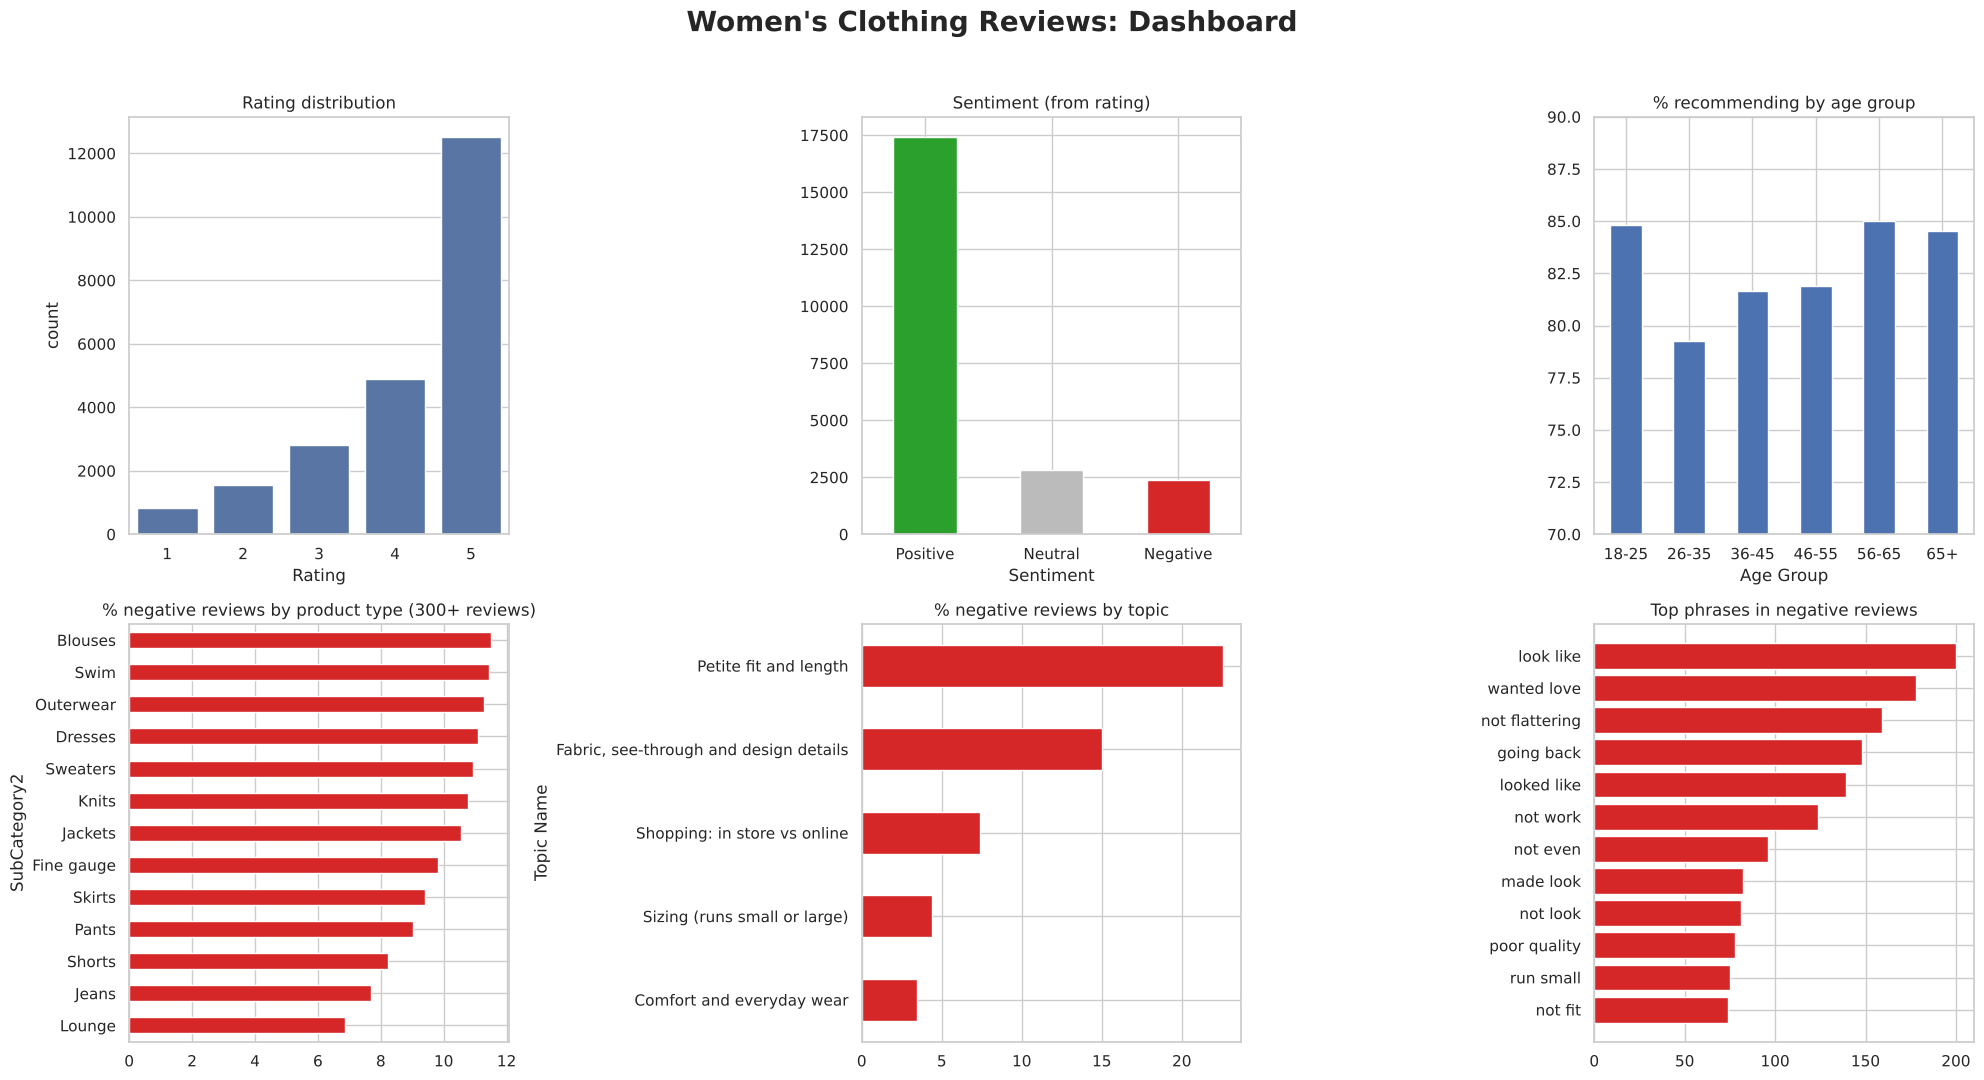

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Women's Clothing Reviews: Dashboard", fontsize=20, fontweight="bold")

sns.countplot(x="Rating", data=df, ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set_title("Rating distribution")

df["Sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).plot(
    kind="bar", ax=axes[0, 1], color=["#2ca02c", "#bbbbbb", "#d62728"], rot=0)
axes[0, 1].set_title("Sentiment (from rating)")

(df.groupby("Age Group", observed=True)["Recommend Flag"].mean() * 100).plot(
    kind="bar", ax=axes[0, 2], color="#4c72b0", rot=0)
axes[0, 2].set_title("% recommending by age group")
axes[0, 2].set_ylim(70, 90)

neg_type = df.groupby("SubCategory2")["Sentiment"].apply(lambda s: (s == "Negative").mean() * 100)
neg_type[df["SubCategory2"].value_counts().reindex(neg_type.index) >= 300].sort_values().plot(
    kind="barh", ax=axes[1, 0], color="#d62728")
axes[1, 0].set_title("% negative reviews by product type (300+ reviews)")

topic_summary["Negative_Pct"].sort_values().plot(kind="barh", ax=axes[1, 1], color="#d62728")
axes[1, 1].set_title("% negative reviews by topic")

labels, counts = zip(*top_ngrams("Negative", (2, 2), 12))
axes[1, 2].barh(labels[::-1], counts[::-1], color="#d62728")
axes[1, 2].set_title("Top phrases in negative reviews")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("13_dashboard.png", dpi=120)
plt.show()

In [38]:
import plotly.express as px

figs = [
    px.histogram(df, x="Rating", color="Channel", barmode="group", title="Ratings by channel"),
    px.bar(pd.crosstab(df["Subcategory1"], df["Sentiment"], normalize="index").mul(100).round(1).reset_index()
             .melt(id_vars="Subcategory1", value_name="% of reviews"),
           x="Subcategory1", y="% of reviews", color="Sentiment", title="Sentiment by subcategory",
           color_discrete_map={"Positive": "#2ca02c", "Neutral": "#bbbbbb", "Negative": "#d62728"}),
    px.bar(df.groupby(["Location", "Age Group"], observed=True)["Recommend Flag"].mean().mul(100).round(1)
             .reset_index(), x="Age Group", y="Recommend Flag", color="Location", barmode="group",
           title="% recommending by age group and location"),
    px.bar(topic_summary.reset_index(), x="Negative_Pct", y="Topic Name", orientation="h",
           title="% negative reviews by topic"),
]
with open("dashboard.html", "w", encoding="utf-8") as f:
    f.write("<html><head><meta charset='utf-8'><title>Clothing Reviews Dashboard</title></head>"
            "<body style='font-family:Arial;margin:20px'><h2>Women's Clothing Reviews: Dashboard</h2>")
    f.write(f"<p>{len(df):,} reviews | average rating {df['Rating'].mean():.2f} | "
            f"{df['Recommend Flag'].mean():.0%} recommend | {(df['Sentiment'] == 'Negative').mean():.0%} negative</p>")
    for i, fig in enumerate(figs):
        f.write(fig.to_html(full_html=False, include_plotlyjs=(i == 0)))
    f.write("</body></html>")
print("Saved dashboard.html")

Saved dashboard.html


## 17. Conclusions

**Business findings**
1. Customers are mostly happy: average rating 4.2, and 82% recommend.
2. **Location and channel do not matter.** Every city and both web and mobile look the same. No need for city-specific action.
3. **Problems are about the product, not the customer.** The text model predicts recommending well (macro F1 about 0.84). The customer-details model (age, city, channel) is no better than guessing.
4. **Top complaints:** petite fit and length, thin or see-through fabric, poor quality, and items that look different from the photo.
5. **Trend** items and **dresses / blouses** get the most negative reviews. Customers aged **26-35** are the most critical.
6. A few single products (for example Product IDs 1084, 870 and 1087) have more than 20% negative reviews. These should be checked first.

**Recommendations for the company**
- Fix petite sizing and length. Add exact measurements for petite items.
- Add "fabric thickness / see-through" information and real-life photos to product pages.
- Add a size advice line ("runs small, order one size up") where reviews keep saying so.
- Use the recommend model to flag new negative reviews automatically, so the customer team can reply fast.

**What I learned**
- The full NLP cleaning pipeline: lower case, contractions, regex, tokens, stopwords (but keep "not"), stemming vs lemmatization.
- Ready-made sentiment tools like VADER can be badly wrong on a new topic (60% of 1-star reviews called "positive").
- Simple TF-IDF + Logistic Regression beat GloVe, FastText, LSTM and GRU on this data size, and it is easy to explain.
- Topic mining (LDA) needs human judgement: remove generic words, test the number of topics with a coherence score, then name the topics by reading the top words.